# Exercício 7 — Teste de Wald para a Poisson

**Enunciado:** Seja $X_1, \dots, X_n \sim \text{Poisson}(\lambda)$.

- (a) Seja $\lambda_0 > 0$. Determine o teste de Wald de tamanho $\alpha$ para $H_0: \lambda = \lambda_0$ versus $H_1: \lambda \neq \lambda_0$.
- (b) Seja $\lambda_0 = 1$, $n = 20$ e $\alpha = 0.05$. Simule $X_1, \dots, X_n \sim \text{Poisson}(\lambda_0)$ e realize o teste de Wald. Repita várias vezes e conte com que frequência a hipótese nula é rejeitada. Quão próxima está a taxa de erro tipo I de $0.05$?

O item (a) está resolvido em [`wald_poisson.pdf`](wald_poisson.pdf). O resultado que uso aqui:
$$W = \frac{\hat\lambda - \lambda_0}{\widehat{\text{se}}}, \qquad \hat\lambda = \overline{X}_n, \qquad \widehat{\text{se}} = \sqrt{\hat\lambda / n},$$
e rejeitamos $H_0$ se $|W| > z_{\alpha/2}$.

## Item (b)

Os dados são gerados com $\lambda = \lambda_0 = 1$, ou seja, $H_0$ é **verdadeira**. Então toda vez que o teste rejeita $H_0$ é um erro tipo I, e a fração de rejeições estima a taxa de erro tipo I.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

lambda0 = 1
n = 20
z = 1.96      # z_{alpha/2} para alpha = 0.05
B = 10_000    # numero de repeticoes

### O teste de Wald

Uma função que recebe uma amostra e devolve o valor de $W$:

In [3]:
def wald(x, lambda0):
    n = len(x)
    lambda_hat = x.mean()
    se_hat = np.sqrt(lambda_hat / n)
    return (lambda_hat - lambda0) / se_hat

### Um teste só

In [4]:
x = rng.poisson(lambda0, n)
W = wald(x, lambda0)

print("amostra:", x)
print(f"W = {W:.3f}")
print("rejeita H0" if abs(W) > z else "nao rejeita H0")

amostra: [1 2 3 1 3 0 1 3 3 1 0 3 1 0 0 1 1 2 2 0]
W = 1.512
nao rejeita H0


### Repetindo $B$ vezes

Para cada repetição: gero uma amostra nova, calculo $W$ e anoto se rejeitou.

In [5]:
Ws = np.zeros(B)

for b in range(B):
    x = rng.poisson(lambda0, n)
    Ws[b] = wald(x, lambda0)

rejeitou = np.abs(Ws) > z
taxa = rejeitou.mean()

print(f"taxa de erro tipo I = {taxa:.4f}")

taxa de erro tipo I = 0.0536


### Quão perto de 0.05?

A taxa simulada também é uma média de $B$ Bernoullis (rejeitou ou não), então tem um erro de simulação:
$$\text{se}_{MC} = \sqrt{\frac{0.05 \cdot 0.95}{B}} \approx 0.0022.$$
Se o tamanho do teste fosse exatamente $0.05$, a taxa simulada deveria cair em $0.05 \pm 2\,\text{se}_{MC}$.

In [6]:
se_mc = np.sqrt(0.05 * 0.95 / B)

print(f"se_MC = {se_mc:.4f}")
print(f"faixa esperada: [{0.05 - 2*se_mc:.4f}, {0.05 + 2*se_mc:.4f}]")

se_MC = 0.0022
faixa esperada: [0.0456, 0.0544]


### A distribuição de $W$ sob $H_0$

O teste supõe que $W \approx N(0, 1)$. Comparando o histograma dos $W$ simulados com a densidade normal:

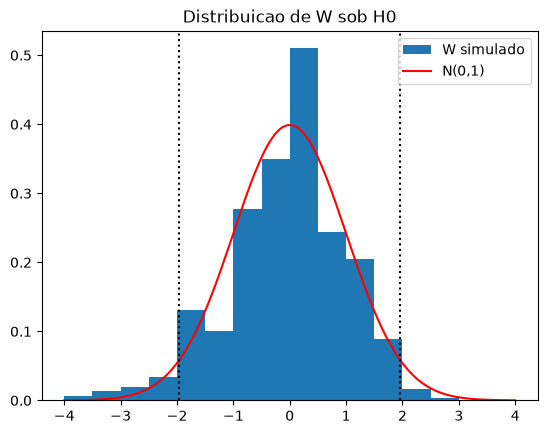

In [7]:
t = np.linspace(-4, 4, 200)
normal = np.exp(-t**2 / 2) / np.sqrt(2 * np.pi)

plt.hist(Ws, bins=16, range=(-4, 4), density=True, label='W simulado')
plt.plot(t, normal, 'r', label='N(0,1)')
plt.axvline(-z, color='k', linestyle=':')
plt.axvline(z, color='k', linestyle=':')
plt.title('Distribuicao de W sob H0')
plt.legend()
plt.show()

## Conclusão

Simulando 10.000 amostras com H₀ verdadeira (λ = 1, n = 20), o teste rejeitou H₀ em 5,36% das vezes, então essa é a taxa de erro tipo I. Ela fica perto de 0,05: está dentro da faixa esperada só pelo erro da simulação (0,0456 a 0,0544), mas na borda de cima, então o teste rejeita um pouco mais do que deveria.

Isso faz sentido porque o α do teste de Wald só vale quando n → ∞, e n = 20 é pequeno. Dá pra ver isso no histograma: W é parecido com uma N(0,1), mas a cauda esquerda é mais pesada, já que quando λ̂ é pequeno o ŝe também é, e o W vai lá pra baixo. Mesmo assim, com n = 20 o teste já funciona bem.